![Capital Bikeshare](path_to_banner)

# Predicting Capital Bikeshare Hourly Demand

This project builds a regression model to predict how many bicycles are needed at each Capital Bikeshare station per hour across Washington DC. The final model (tuned HistGradientBoostingRegressor) explains 65.2% of test-set variance (MAE 0.599 rides/station-hour) and is pickled for deployment. At the station-day aggregate level, WAPE drops to 18.2%, making it practical for daily rebalancing schedules.

## Business Understanding

### The Problem
Capital Bikeshare needs to accurately predict demand for bicycles across their network. Without accurate predictions, stations run empty during peak hours or overflow with unused bikes, leading to poor user experience and inefficient operations.

### Stakeholders
- **Bikeshare Operators**: Better fleet redistribution reduces empty/overflow stations and operational costs
- **City Planners**: Effective bike share reduces traffic congestion and supports urban mobility goals
- **Users**: Reliable bike availability improves adoption and satisfaction

### Business Objective
Reliably predict hourly bicycle demand at each station to inform proactive fleet rebalancing decisions.

### Why Machine Learning?
Demand depends on multiple interacting factors — time of day, day of week, weather conditions, station location, and user type. A machine learning model can capture these complex, non-linear relationships better than simple rules or averages.

### Success Metrics
- **Technical**: RMSE and MAE (interpretable as "number of bicycles off"), R² (variance explained)
- **Business**: Reduction in stock-out events, improved user satisfaction scores

In [1]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, TimeSeriesSplit, cross_val_score, RandomizedSearchCV
from sklearn.model_selection import KFold
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.preprocessing import TargetEncoder, FunctionTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

In [2]:
# Set random seed
np.random.seed(42)

## Data Understanding

We have two data sources:
1. **Bikeshare trip data** - 6 months of individual ride records (March–August 2026), ~3.65M rows
2. **Weather data** - Hourly weather observations for Washington DC from the Open-Meteo API

Our target variable will be the count of rides starting at each station per hour

In [3]:
# Load combined bikeshare data
df_bike = pd.read_csv("Bikeshare Data/combined_bikeshare.csv")
print(f"Bikeshare data shape: {df_bike.shape}")

# Load weather data
df_weather = pd.read_csv("Weather Data/dc_weather_hourly.csv", parse_dates=["time"])
print(f"Weather data shape: {df_weather.shape}")

Bikeshare data shape: (3654494, 13)
Weather data shape: (4416, 7)


In [4]:
# Bikeshare data overview
print("=== Bikeshare Data ===")
print(f"\nColumn dtypes:\n{df_bike.dtypes}")

=== Bikeshare Data ===

Column dtypes:
ride_id                   str
rideable_type             str
started_at                str
ended_at                  str
start_station_name        str
start_station_id      float64
end_station_name          str
end_station_id        float64
start_lat             float64
start_lng             float64
end_lat               float64
end_lng               float64
member_casual             str
dtype: object


In [5]:
print(f"\nNull counts:\n{df_bike.isnull().sum()}")


Null counts:
ride_id                    0
rideable_type              0
started_at                 0
ended_at                   0
start_station_name    525278
start_station_id      525278
end_station_name      552873
end_station_id        553847
start_lat                  0
start_lng                  0
end_lat                 2404
end_lng                 2404
member_casual              0
dtype: int64


In [6]:
print(f"\nDate range: {df_bike['started_at'].min()} to {df_bike['started_at'].max()}")
print(f"\nUnique start stations: {df_bike['start_station_id'].nunique()}")


Date range: 2026-02-27 23:12:11.997 to 2026-08-31 23:51:53.486

Unique start stations: 871


In [7]:
# Weather data overview
print("=== Weather Data ===")
print(f"\nColumn dtypes:\n{df_weather.dtypes}")
print(f"\nNull counts:\n{df_weather.isnull().sum()}")
print(f"\nDate range: {df_weather['time'].min()} to {df_weather['time'].max()}")
print(f"\nDescriptive statistics:")
df_weather.describe()

=== Weather Data ===

Column dtypes:
time                    datetime64[us]
temperature_2m                 float64
relative_humidity_2m             int64
precipitation                  float64
weather_code                     int64
wind_speed_10m                 float64
cloud_cover                      int64
dtype: object

Null counts:
time                    0
temperature_2m          0
relative_humidity_2m    0
precipitation           0
weather_code            0
wind_speed_10m          0
cloud_cover             0
dtype: int64

Date range: 2026-03-01 00:00:00 to 2026-08-31 23:00:00

Descriptive statistics:


,time,temperature_2m,relative_humidity_2m,precipitation,weather_code,wind_speed_10m,cloud_cover
count,4416,4416.000000,4416.000000,4416.000000,4416.000000,4416.000000,4416.000000
mean,2026-05-31 23:30:00,20.184986,65.693388,0.153351,11.340806,9.611368,55.519701
min,2026-03-01 00:00:00,-4.000000,15.000000,0.000000,0.000000,0.000000,0.000000
25%,2026-04-15 23:45:00,14.700000,48.000000,0.000000,0.000000,6.000000,10.000000
50%,2026-05-31 23:30:00,21.900000,66.000000,0.000000,2.000000,8.800000,62.000000
75%,2026-07-16 23:15:00,25.800000,84.000000,0.000000,3.000000,12.600000,99.000000
max,2026-08-31 23:00:00,39.600000,100.000000,11.800000,75.000000,32.500000,100.000000
std,NaN,8.048533,21.238999,0.632762,20.655214,4.981726,40.852413


It looks like we will need to convert the weather_code into something more readable than an int, as the weather code can be used to represent a wide set of conditions

#### Initial Observations and Cleaning of Valid Times

In [8]:
# Prepare time features
df_bike["started_at"] = pd.to_datetime(df_bike["started_at"], errors="coerce")
invalid_started_at = df_bike["started_at"].isna().sum()
df_bike = df_bike.dropna(subset=["started_at"]).copy()
df_bike["started_hour"] = df_bike["started_at"].dt.floor("h")
df_bike["hour"] = df_bike["started_at"].dt.hour
df_bike["dayofweek"] = df_bike["started_at"].dt.dayofweek
df_bike["day_name"] = df_bike["started_at"].dt.day_name()
df_bike["month"] = df_bike["started_at"].dt.month
df_bike["month_name"] = df_bike["started_at"].dt.strftime("%b")

day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
month_order = (
    df_bike[["month", "month_name"]]
    .drop_duplicates()
    .sort_values("month")["month_name"]
    .tolist()
)

print(f"Rows available for temporal EDA: {len(df_bike):,}")
print(f"Invalid start timestamps removed: {invalid_started_at:,}")

Rows available for temporal EDA: 3,654,494
Invalid start timestamps removed: 0


=== Temporal demand diagnostics ===
Peak hour: 17:00
Peak day: Saturday
Highest-volume month: Jun


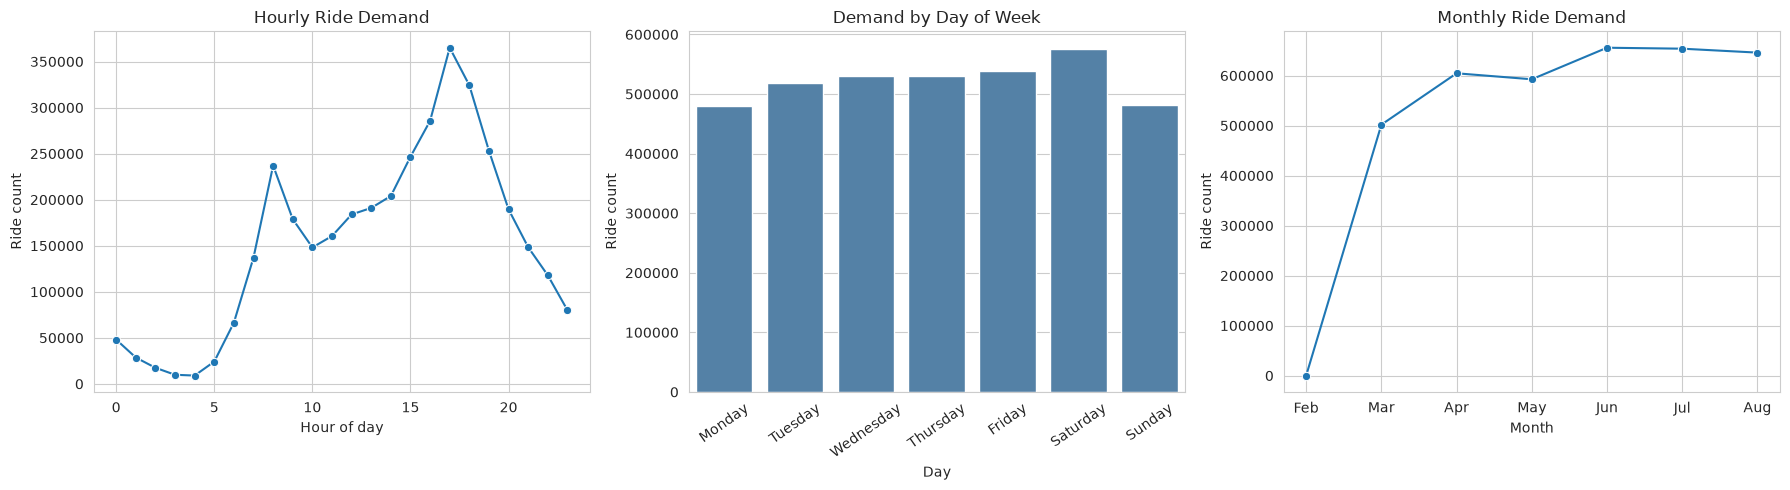

In [9]:
# Aggregate total rides by time period
hourly_temporal_demand = df_bike.groupby("hour").size().reset_index(name="ride_count")
daily_temporal_demand = (
    df_bike.groupby(["dayofweek", "day_name"]).size()
    .reset_index(name="ride_count")
    .sort_values("dayofweek")
)
monthly_temporal_demand = (
    df_bike.groupby(["month", "month_name"]).size()
    .reset_index(name="ride_count")
    .sort_values("month")
)

print("=== Temporal demand diagnostics ===")
print(f"Peak hour: {hourly_temporal_demand.loc[hourly_temporal_demand['ride_count'].idxmax(), 'hour']}:00")
print(f"Peak day: {daily_temporal_demand.loc[daily_temporal_demand['ride_count'].idxmax(), 'day_name']}")
print(f"Highest-volume month: {monthly_temporal_demand.loc[monthly_temporal_demand['ride_count'].idxmax(), 'month_name']}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.lineplot(data=hourly_temporal_demand, x="hour", y="ride_count", marker="o", ax=axes[0])
axes[0].set(title="Hourly Ride Demand", xlabel="Hour of day", ylabel="Ride count")
sns.barplot(data=daily_temporal_demand, x="day_name", y="ride_count", order=day_order, ax=axes[1], color="steelblue")
axes[1].set(title="Demand by Day of Week", xlabel="Day", ylabel="Ride count")
axes[1].tick_params(axis="x", rotation=35)
sns.lineplot(data=monthly_temporal_demand, x="month_name", y="ride_count", marker="o", ax=axes[2])
axes[2].set(title="Monthly Ride Demand", xlabel="Month", ylabel="Ride count")
axes[2].set_xticks(range(len(month_order)), month_order)
plt.tight_layout()
plt.show()

The hour curve shows two sharp peaks at 8 in the morning and 5 in the afternoon, which does correlate with rush hour traffic. One of the more interesting trends is that ridership is much higher in the afternoon than in the morning. There may be a few groups of people involved, first may be school children who have left school using the bicycles and another potential group may be workers returning from work making multiple trips to visit a few locations before returning home. Saturday has the most ridership by a small margin, while Sunday has the fewest alongside Monday. Saturday is likely due to people using the bicycles casually on the primary day of the weekend. I am not fully certain why Sunday and Monday have much smaller usage rates. On the monthly side of things, ignoring the small 106 rides that began during February, the overall ridership does show an increase in ridership as the summer approaches, with a small decline in August.

=== Member versus casual diagnostics ===
member_casual
casual    1098876
member    2555618
Name: ride_count, dtype: int64


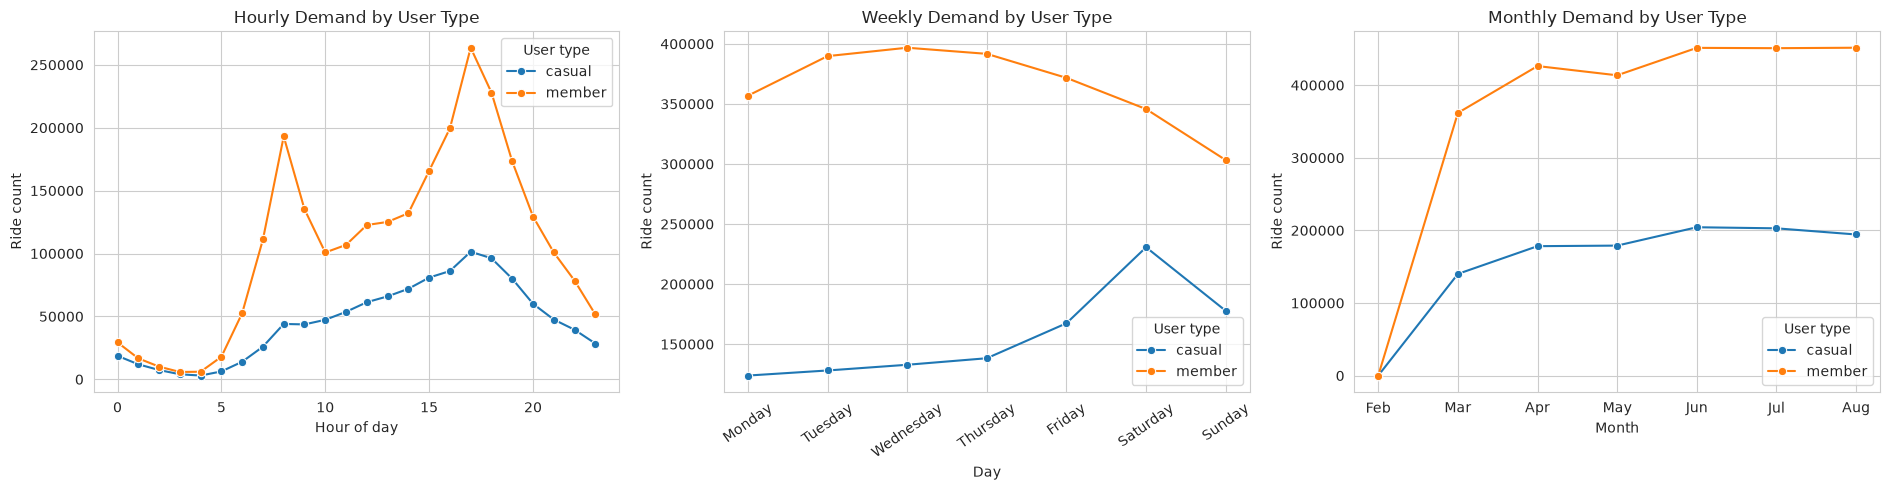

In [10]:
# Compare member and casual demand
member_temporal_demand = (
    df_bike.groupby(["member_casual", "hour"]).size()
    .reset_index(name="ride_count")
)
member_day_demand = (
    df_bike.groupby(["member_casual", "dayofweek", "day_name"]).size()
    .reset_index(name="ride_count")
)
member_month_demand = (
    df_bike.groupby(["member_casual", "month", "month_name"]).size()
    .reset_index(name="ride_count")
)

print("=== Member versus casual diagnostics ===")
print(member_temporal_demand.groupby("member_casual")["ride_count"].sum())

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
sns.lineplot(data=member_temporal_demand, x="hour", y="ride_count", hue="member_casual", marker="o", ax=axes[0])
axes[0].set(title="Hourly Demand by User Type", xlabel="Hour of day", ylabel="Ride count")
sns.lineplot(data=member_day_demand.sort_values("dayofweek"), x="day_name", y="ride_count", hue="member_casual", marker="o", ax=axes[1])
axes[1].set(title="Weekly Demand by User Type", xlabel="Day", ylabel="Ride count")
axes[1].set_xticks(range(7), day_order, rotation=35)
sns.lineplot(data=member_month_demand.sort_values("month"), x="month_name", y="ride_count", hue="member_casual", marker="o", ax=axes[2])
axes[2].set(title="Monthly Demand by User Type", xlabel="Month", ylabel="Ride count")
axes[2].set_xticks(range(len(month_order)), month_order)
for axis in axes:
    axis.legend(title="User type")
plt.tight_layout()
plt.show()

Initial Notes

Casual ridership is a muted variant of member ridership for hourly demand, seeing a slow increase over the day, though a minor jump at 8 AM.
On the weekly data, we see an inversion between members and casual riders, with membership riders peaking on Wednesdays with a gentle curve. The casual data instead increase over the week, resulting in a strong peak on Saturday which decreases on Sunday.
Monthly data has the two groups effectively look the same, just scaled slightly, thought there is a noticable dent in May usage, especially among members, possibly weather related.

=== Top 15 origin stations ===
 start_station_id                   station_label  ride_count  ride_percentage
          31623.0 Columbus Circle / Union Station       33616         1.074263
          31229.0     New Hampshire Ave & T St NW       30398         0.971425
          31124.0             14th & Irving St NW       27839         0.889648
          31699.0            Eastern Market Metro       26451         0.845292
          31201.0                  15th & P St NW       26017         0.831422
          31600.0                   5th & K St NW       24564         0.784989
          31101.0                  14th & V St NW       24196         0.773229
          31603.0                   1st & M St NE       22359         0.714524
          31532.0            4th & Florida Ave NE       21424         0.684644
          31119.0            14th & Belmont St NW       21258         0.679339
          31627.0          M St & Delaware Ave NE       21203         0.677582
          31104.0    

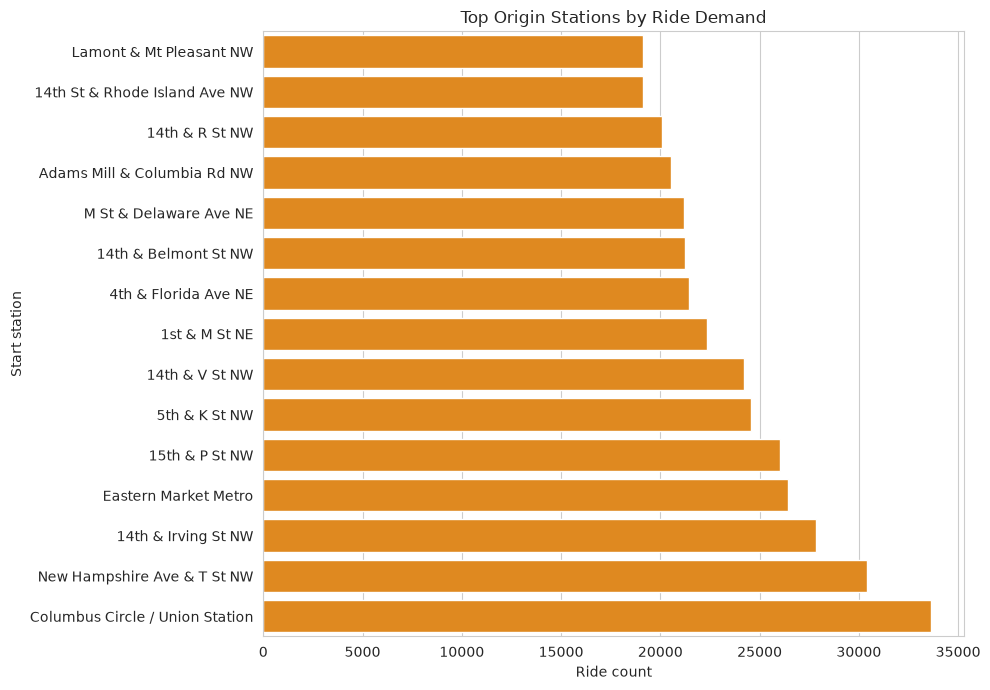

In [11]:
# Rank stations by originating rides
top_stations = (
    df_bike.dropna(subset=["start_station_id"])
    .groupby(["start_station_id", "start_station_name"], dropna=False)
    .size()
    .reset_index(name="ride_count")
    .sort_values("ride_count", ascending=False)
    .head(15)
)
top_stations["station_label"] = top_stations["start_station_name"].fillna("Unknown station")
total_rides = df_bike["start_station_id"].notna().sum()
top_stations["ride_percentage"] = top_stations["ride_count"] * 100 / total_rides

print("=== Top 15 origin stations ===")
print(top_stations[["start_station_id", "station_label", "ride_count", "ride_percentage"]].to_string(index=False))

plt.figure(figsize=(10, 7))
sns.barplot(data=top_stations.sort_values("ride_count"), x="ride_count", y="station_label", color="darkorange")
plt.title("Top Origin Stations by Ride Demand")
plt.xlabel("Ride count")
plt.ylabel("Start station")
plt.tight_layout()
plt.show()

It does appear that the trips are quite evenly spread across the network. The most used station, Columbus Circle / Union Station only composes 33616 rides, or approximately 1% of the total rides over the 6 month period. This suggests that these top stations do not make up too much of the dataset, allowing for a more useful analysis. I think it would be best to continue confirm this looking over the entire dataset.

Total stations: 881
Stations needed for 95% of rides: 459
That's 52.1% of all stations


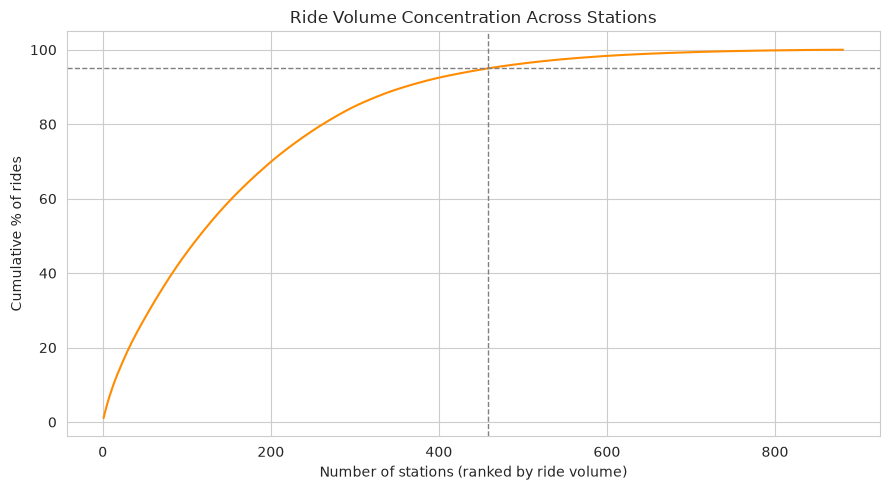

In [12]:
station_counts = (
    df_bike.dropna(subset=["start_station_id"])
    .groupby(["start_station_id", "start_station_name"], dropna=False)
    .size()
    .reset_index(name="ride_count")
    .sort_values("ride_count", ascending=False)
    .reset_index(drop=True)
)

total_rides = station_counts["ride_count"].sum()
station_counts["cumulative_pct"] = station_counts["ride_count"].cumsum() * 100 / total_rides

n_stations_95 = (station_counts["cumulative_pct"] < 95).sum() + 1
total_stations = len(station_counts)

print(f"Total stations: {total_stations}")
print(f"Stations needed for 95% of rides: {n_stations_95}")
print(f"That's {n_stations_95 / total_stations * 100:.1f}% of all stations")

plt.figure(figsize=(9, 5))
plt.plot(range(1, total_stations + 1), station_counts["cumulative_pct"], color="darkorange")
plt.axhline(95, color="gray", linestyle="--", linewidth=1)
plt.axvline(n_stations_95, color="gray", linestyle="--", linewidth=1)
plt.xlabel("Number of stations (ranked by ride volume)")
plt.ylabel("Cumulative % of rides")
plt.title("Ride Volume Concentration Across Stations")
plt.tight_layout()
plt.show()

The curve does confirm that largest stations do not dominate the dataset. 459 stations make up the sources for 95% of all rides. This means that the most will need to generalize well across the entire tail of lower to medium volume stations than only focusing on the top stations. This should mean that the model will work well across the entire network. There is an oddity here that it is reporting 881 station names instead of the previous 871 station IDs, but I have found the cause which I elaborate on below.

In [13]:
name_counts_per_id = df_bike.dropna(subset=["start_station_id"]).groupby("start_station_id")["start_station_name"].nunique()
name_counts_per_id[name_counts_per_id > 1]

start_station_id
31293.0    2
31407.0    3
31415.0    2
31937.0    2
31971.0    4
32340.0    2
32364.0    2
Name: start_station_name, dtype: int64

So 7 station IDs have alternate names, so we need to check that those alternate names are just variants instead of stations being shut down and new stations taking the ID number, as that would damage the prediction, though it depends on the traffic of these stations.

In [14]:
name_counts_per_id = (
    df_bike.dropna(subset=["start_station_id"])
    .groupby("start_station_id")["start_station_name"]
    .nunique()
)
multi_name_ids = name_counts_per_id[name_counts_per_id > 1].index

variants = (
    df_bike[df_bike["start_station_id"].isin(multi_name_ids)]
    .groupby(["start_station_id", "start_station_name"])
    .size()
    .reset_index(name="ride_count")
    .sort_values(["start_station_id", "ride_count"], ascending=[True, False])
)
print(variants.to_string(index=False))

 start_station_id                       start_station_name  ride_count
          31293.0                           31st & K St NW        3876
          31293.0   Thomas Jefferson St NW & Water/K St NW        1472
          31407.0                14th St & Colorado Ave NW        3027
          31407.0          Colorado Ave & Longfellow St NW        1016
          31407.0                   14th & Colorado Ave Nw          71
          31415.0           Georgia Ave & Longfellow St NW         990
          31415.0              Georgia Ave & Kennedy St NW         247
          31937.0              Arlington Blvd & Ft Myer Dr        1093
          31937.0                12th St N & Fort Myer Dr.         759
          31971.0   Penrose Sq/Columbia Pike & S Barton St         458
          31971.0 Penrose Sq / Columbia Pike & S Barton St         311
          31971.0                  S Wayne St and 9th St S         142
          31971.0   Penrose Square / S Wayne St & 9th St S           1
      

Most of the repeated stations are just different spellings and overall there are very few rides compared to the total of over 3 million. Some of the locations do appear different, but looking them up shows that most of these are just another way to name the location or our within a block or two of each other, likely suggesting that these are just stations that were moved for slight improvements in throughput or due to construction.

In [15]:
canonical_names = (
    df_bike.dropna(subset=["start_station_id"])
    .groupby(["start_station_id", "start_station_name"])
    .size()
    .reset_index(name="n")
    .sort_values("n", ascending=False)
    .drop_duplicates(subset="start_station_id")
    .set_index("start_station_id")["start_station_name"]
)

df_bike["start_station_name"] = df_bike["start_station_id"].map(canonical_names).fillna(df_bike["start_station_name"])

In [16]:
# Select the most common name for each destination ID
end_name_counts = (
    df_bike.dropna(subset=["end_station_id", "end_station_name"])
    .groupby(["end_station_id", "end_station_name"])
    .size()
    .reset_index(name="n")
    .sort_values(["end_station_id", "n"], ascending=[True, False])
)
end_canonical_names = (
    end_name_counts.drop_duplicates(subset="end_station_id")
    .set_index("end_station_id")["end_station_name"]
)

end_name_before = df_bike["end_station_name"].copy()
df_bike["end_station_name"] = (
    df_bike["end_station_id"].map(end_canonical_names)
    .fillna(df_bike["end_station_name"])
)
end_name_changed = (
    df_bike["end_station_id"].notna()
    & end_name_before.notna()
    & df_bike["end_station_name"].notna()
    & end_name_before.ne(df_bike["end_station_name"])
)

print("=== End station canonical mapping diagnostics ===")
print(f"Unique end station IDs with a name: {len(end_canonical_names):,}")
print(f"End station names cleaned up: {end_name_changed.sum():,}")
print(f"End station name nulls after mapping: {df_bike['end_station_name'].isna().sum():,}")
print("Examples of changed names:")
print(pd.DataFrame({"before": end_name_before[end_name_changed], "after": df_bike.loc[end_name_changed, "end_station_name"]}).drop_duplicates().head(10).to_string())

=== End station canonical mapping diagnostics ===
Unique end station IDs with a name: 871
End station names cleaned up: 4,265
End station name nulls after mapping: 552,873
Examples of changed names:
                                           before                                   after
139               Colorado Ave & Longfellow St NW               14th St & Colorado Ave NW
143                        14th & Colorado Ave Nw               14th St & Colorado Ave NW
3424                      S Wayne St and 9th St S  Penrose Sq/Columbia Pike & S Barton St
13017      Thomas Jefferson St NW & Water/K St NW                          31st & K St NW
403616                Georgia Ave & Kennedy St NW          Georgia Ave & Longfellow St NW
1256238                Wakefield Dr & Potomac ave              Wakefield Dr & Potomac Ave
1699480                 12th St N & Fort Myer Dr.             Arlington Blvd & Ft Myer Dr
2369652  Penrose Sq / Columbia Pike & S Barton St  Penrose Sq/Columbia Pike & S B

=== Weather merge diagnostics ===
Station-hour rows: 1,100,876
Total hourly demand rows: 4,430
Merged hourly rows: 4,415
Weather match rate: 99.7%

Numeric correlations with hourly ride demand:
temperature_2m          0.403926
wind_speed_10m          0.074941
precipitation          -0.041304
weather_code           -0.042305
cloud_cover            -0.046276
relative_humidity_2m   -0.514990
Name: ride_count, dtype: float64


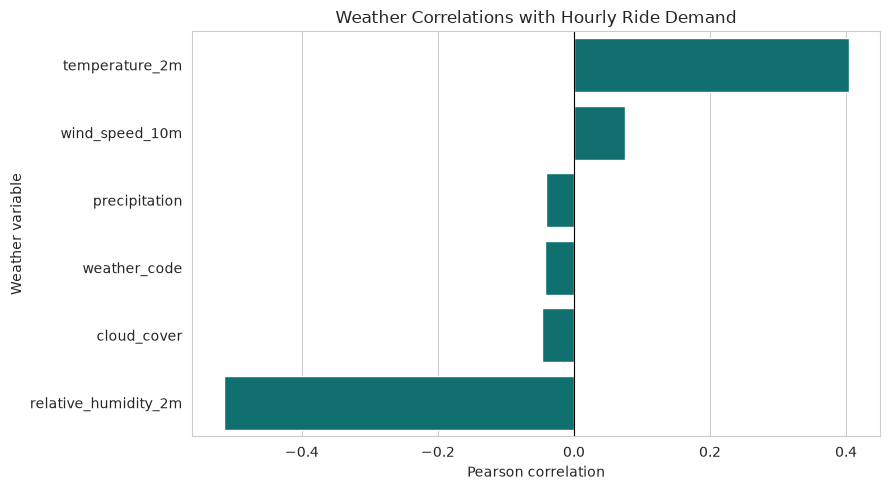

In [17]:
# Build station-hour demand before joining weather
hourly_station_demand = (
    df_bike.dropna(subset=["start_station_id"])
    .groupby(["started_hour", "start_station_id"], as_index=False)
    .size()
    .rename(columns={"size": "ride_count"})
)
hourly_demand = (
    hourly_station_demand.groupby("started_hour", as_index=False)["ride_count"]
    .sum()
    .rename(columns={"started_hour": "time"})
)

# Align timestamps for the weather join
df_weather["time"] = pd.to_datetime(df_weather["time"], errors="coerce")
df_weather["time"] = df_weather["time"].dt.tz_localize(None).dt.floor("h")
hourly_weather_demand = hourly_demand.merge(df_weather, on="time", how="inner")

print("=== Weather merge diagnostics ===")
print(f"Station-hour rows: {len(hourly_station_demand):,}")
print(f"Total hourly demand rows: {len(hourly_demand):,}")
print(f"Merged hourly rows: {len(hourly_weather_demand):,}")
print(f"Weather match rate: {len(hourly_weather_demand) / len(hourly_demand):.1%}")
print("\nNumeric correlations with hourly ride demand:")
weather_correlations = (
    hourly_weather_demand.select_dtypes(include="number")
    .corr()["ride_count"]
    .drop("ride_count")
    .sort_values(ascending=False)
)
print(weather_correlations)

plt.figure(figsize=(9, 5))
sns.barplot(x=weather_correlations.values, y=weather_correlations.index, color="teal")
plt.title("Weather Correlations with Hourly Ride Demand")
plt.xlabel("Pearson correlation")
plt.ylabel("Weather variable")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

Humidity has the strongest correlation and a negative correlation with hourly rides, which is quite interesting. This may be due to it having a strong correlation to the time of day, which confounds its impact. The strongest positive correlation relates to termperature, which makes sense, as bicycles are not climate controlled like cars or trains. We should also note that it is interesting that the correlation between precipitation is about the same as it is with the weather code. The weather code is not a fully meaningful number, which asks whether or not the precipitation actually has a major impact.

In [18]:
def bucket_weather_code(code):
    if code == 0:
        return "clear"
    elif code in [1, 2, 3]:
        return "cloudy"
    elif code in [45, 48]:
        return "fog"
    elif code in range(51, 68):  # drizzle/rain codes
        return "rain"
    elif code in range(71, 87):  # snow codes
        return "snow"
    elif code in range(95, 100):
        return "thunderstorm"
    else:
        return "other"

df_weather["weather_category"] = df_weather["weather_code"].apply(bucket_weather_code)

## Null-location rides investigation

A substantial group of rides has no recorded start station, which is likely related to the dockless mode that e-bikes support.

In [19]:
# Isolate rides without a start station
df_null_start = df_bike[df_bike["start_station_id"].isna()].copy()
df_null_start["ended_at_parsed"] = pd.to_datetime(df_null_start["ended_at"], errors="coerce")
df_null_start["null_start_duration_minutes"] = (
    df_null_start["ended_at_parsed"] - df_null_start["started_at"]
).dt.total_seconds() / 60

coords_available = df_null_start[["start_lat", "start_lng", "end_lat", "end_lng"]].notna().all(axis=1)
same_coordinates = (
    np.isclose(df_null_start["start_lat"], df_null_start["end_lat"], equal_nan=False)
    & np.isclose(df_null_start["start_lng"], df_null_start["end_lng"], equal_nan=False)
)

print("=== Null-start ride diagnostics ===")
print(f"Shape: {df_null_start.shape}")
print(f"Member/casual split:\n{df_null_start['member_casual'].value_counts(dropna=False)}")
print(f"Coordinate pairs available: {coords_available.sum():,} ({coords_available.mean():.1%})")
print(f"Start and end coordinates match: {(same_coordinates & coords_available).sum():,} ({(same_coordinates & coords_available).mean():.1%} of all null-start rides)")
print(f"Null duration values: {df_null_start['null_start_duration_minutes'].isna().sum():,}")
print("Duration summary (minutes):")
print(df_null_start["null_start_duration_minutes"].describe())
print("Sample rows:")
print(df_null_start[["ride_id", "started_at", "ended_at", "start_lat", "start_lng", "end_lat", "end_lng", "member_casual"]].head(5).to_string(index=False))

=== Null-start ride diagnostics ===
Shape: (525278, 21)
Member/casual split:
member_casual
member    373063
casual    152215
Name: count, dtype: int64
Coordinate pairs available: 525,278 (100.0%)
Start and end coordinates match: 86,525 (16.5% of all null-start rides)
Null duration values: 0
Duration summary (minutes):
count    525278.000000
mean         10.574685
std          12.266335
min           0.000567
25%           4.121150
50%           7.874500
75%          13.500850
max         479.973233
Name: null_start_duration_minutes, dtype: float64
Sample rows:
         ride_id              started_at                ended_at  start_lat  start_lng   end_lat    end_lng member_casual
DD0D646BA69C7189 2026-03-27 08:59:06.074 2026-03-27 09:04:22.879      38.91     -77.03 38.903967 -77.034602        member
579355D6147F7A0A 2026-03-31 21:25:20.667 2026-03-31 21:34:30.174      38.90     -77.06 38.918103 -77.045469        member
2AF92C442028C73D 2026-03-15 16:52:46.255 2026-03-15 16:54:41.273   

These rows do seem to match with the dockless mode. Since we are modeling demand at a station level, it would be best to drop them for overall station demand. We can keep it when analyzing total ride volume.

## Ride duration analysis

Ride duration is useful for identifying bad records and for understanding how member and casual users use the service.

=== Ride duration diagnostics ===
Duration nulls: 0
Negative durations: 0
Durations over 120 minutes: 14,516
Duration summary (all non-null rides):
count    3.654494e+06
mean     1.407414e+01
std      4.463133e+01
min      5.666667e-04
25%      5.229854e+00
50%      8.892267e+00
75%      1.491332e+01
max      1.559948e+03
Name: ride_duration_minutes, dtype: float64


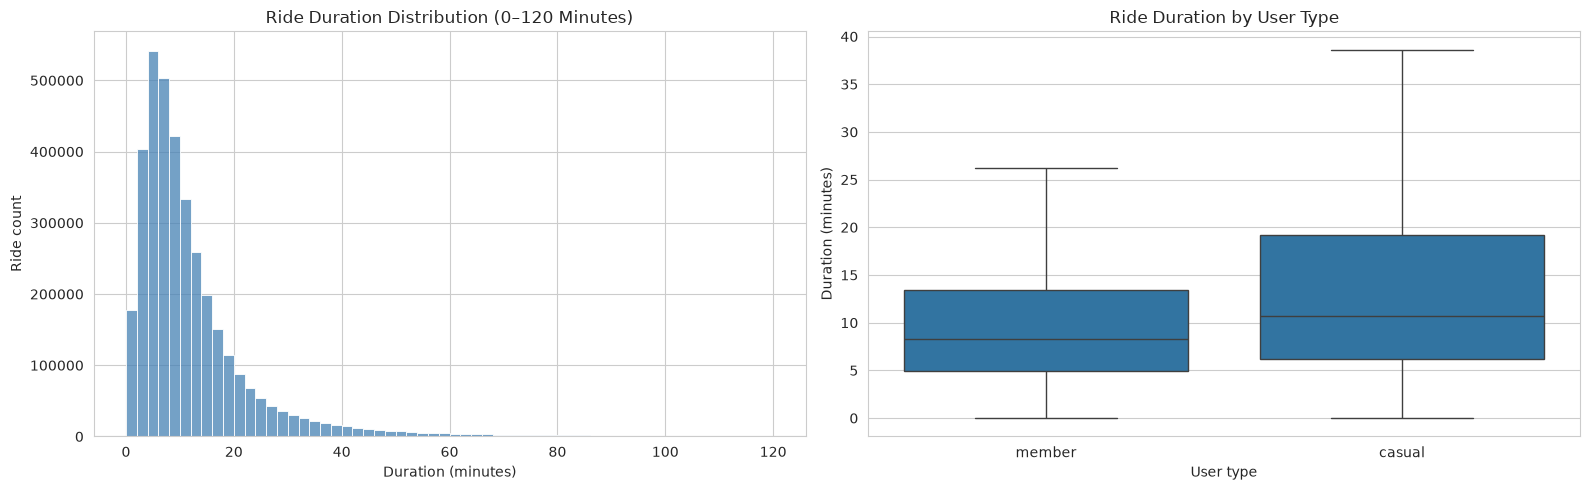

Median duration by user type:
member_casual
casual    10.689383
member     8.239933
Name: ride_duration_minutes, dtype: float64


In [20]:
# Parse end times and calculate duration
df_bike["ended_at_parsed"] = pd.to_datetime(df_bike["ended_at"], errors="coerce")
df_bike["ride_duration_minutes"] = (
    df_bike["ended_at_parsed"] - df_bike["started_at"]
).dt.total_seconds() / 60

duration_stats = df_bike["ride_duration_minutes"].describe()
negative_duration_count = (df_bike["ride_duration_minutes"] < 0).sum()
extreme_duration_count = (df_bike["ride_duration_minutes"] > 120).sum()

print("=== Ride duration diagnostics ===")
print(f"Duration nulls: {df_bike['ride_duration_minutes'].isna().sum():,}")
print(f"Negative durations: {negative_duration_count:,}")
print(f"Durations over 120 minutes: {extreme_duration_count:,}")
print("Duration summary (all non-null rides):")
print(duration_stats)

df_valid_duration = df_bike[
    df_bike["ride_duration_minutes"].notna()
    & df_bike["ride_duration_minutes"].between(0, 120)
].copy()
df_valid_duration["duration_plot_minutes"] = df_valid_duration["ride_duration_minutes"].clip(upper=120)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.histplot(data=df_valid_duration, x="duration_plot_minutes", bins=60, color="steelblue", ax=axes[0])
axes[0].set(title="Ride Duration Distribution (0–120 Minutes)", xlabel="Duration (minutes)", ylabel="Ride count")
sns.boxplot(data=df_valid_duration, x="member_casual", y="ride_duration_minutes", order=["member", "casual"], showfliers=False, ax=axes[1])
axes[1].set(title="Ride Duration by User Type", xlabel="User type", ylabel="Duration (minutes)")
plt.tight_layout()
plt.show()

print("Median duration by user type:")
print(df_valid_duration.groupby("member_casual")["ride_duration_minutes"].median())

Most rides last less than 20 minutes with the largest number of rides being between 4 and 6 minutes, showing that most rides are pretty short. There are a tiny percentage of rides that last longer than an hour, with only 14 thousand over 2 hours. Casual riders have a wider bracekt or riders with a longer average ride length, which does suggest members are using the bicycles regularly and taking shorter routes. The casual riders having longer average rides does reduce overall network availability when they are the more common.

## Weather category and hourly demand

=== Weather category demand diagnostics ===
Hourly weather shape: (4430, 3)
Weather category nulls: 15
Hourly demand by weather category:
                  count        mean  median  min   max
weather_category                                      
cloudy             2259  733.143426   694.0    1  2704
clear              1327  693.812359   628.0    3  2590
rain                813  673.314883   624.0   10  2518
snow                 16  304.125000   294.5   95   679


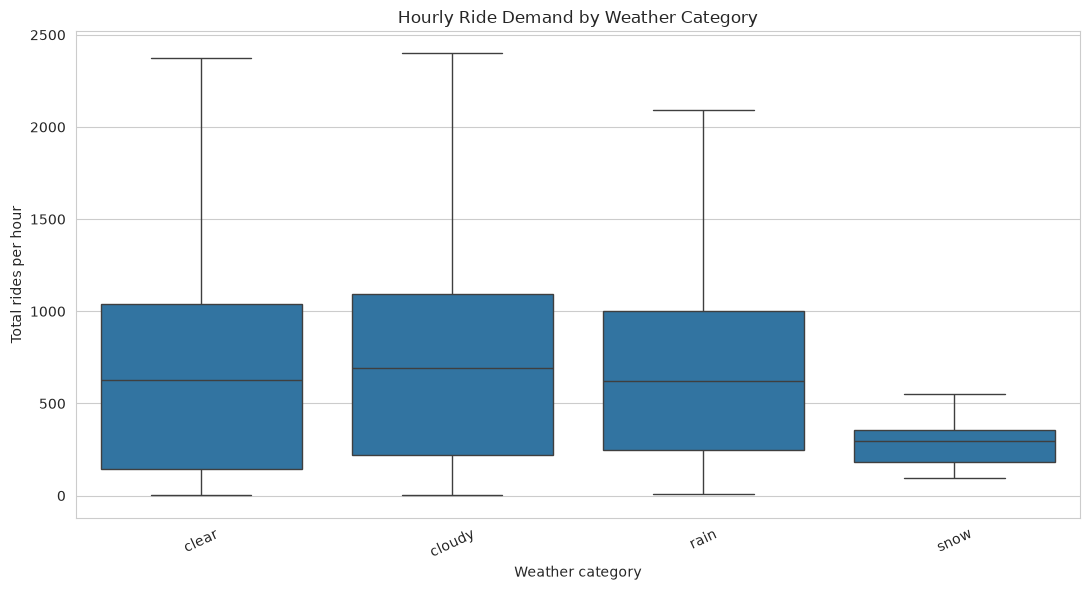

In [21]:
# Join weather categories to total hourly demand
hourly_weather = hourly_demand.merge(
    df_weather[["time", "weather_category"]].drop_duplicates("time"),
    on="time",
    how="left"
)

print("=== Weather category demand diagnostics ===")
print(f"Hourly weather shape: {hourly_weather.shape}")
print(f"Weather category nulls: {hourly_weather['weather_category'].isna().sum():,}")
print("Hourly demand by weather category:")
print(hourly_weather.groupby("weather_category")["ride_count"].agg(["count", "mean", "median", "min", "max"]).sort_values("mean", ascending=False))

weather_order = ["clear", "cloudy", "fog", "rain", "snow", "thunderstorm", "other"]
weather_order = [category for category in weather_order if category in hourly_weather["weather_category"].dropna().unique()]
plt.figure(figsize=(11, 6))
sns.boxplot(data=hourly_weather.dropna(subset=["weather_category"]), x="weather_category", y="ride_count", order=weather_order, showfliers=False)
plt.title("Hourly Ride Demand by Weather Category")
plt.xlabel("Weather category")
plt.ylabel("Total rides per hour")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

Overall there is quite an intersting trend here, as the number of rides is not much lower than in the other weather conditions. This may suggest a few possibilities, first is that the weather information for DC does not accurately cover the entire coverage network, so rain at the weather station does not actually impact most of the network. Another possibility is that rides are just less suppressed than one would think, as the overall bike ride is relatively short and likely cheaper than choosing a drier form of transportation. Snow though does see a major decrease in rides per hour.

## Temperature versus demand

Temperature may have a non-linear relationship with ridership, as demand can increase as cold weather becomes comfortable, and then decline as the temperature reaches unbearable heat.

=== Temperature-demand diagnostics ===
Rows used: 4,415
Temperature range: -4.0 to 39.6 °C
Temperature-bin demand summary:
 temperature_bin_start  temperature_c  mean_demand  hours
                  -4.0      -3.116667   258.416667     12
                  -2.0      -0.804348   289.847826     46
                   0.0       0.927586   330.086207     58
                   2.0       3.017647   418.397059     68
                   4.0       5.023810   296.452381     84
                   6.0       6.950407   388.195122    123
                   8.0       9.020859   467.815951    163
                  10.0      11.018966   530.741379    232
                  12.0      12.921834   544.694323    229
                  14.0      14.932127   654.493213    221
                  16.0      17.005328   565.983607    244
                  18.0      19.031834   573.304498    289
                  20.0      21.012473   564.645514    457
                  22.0      22.953301   520.692432    621
       

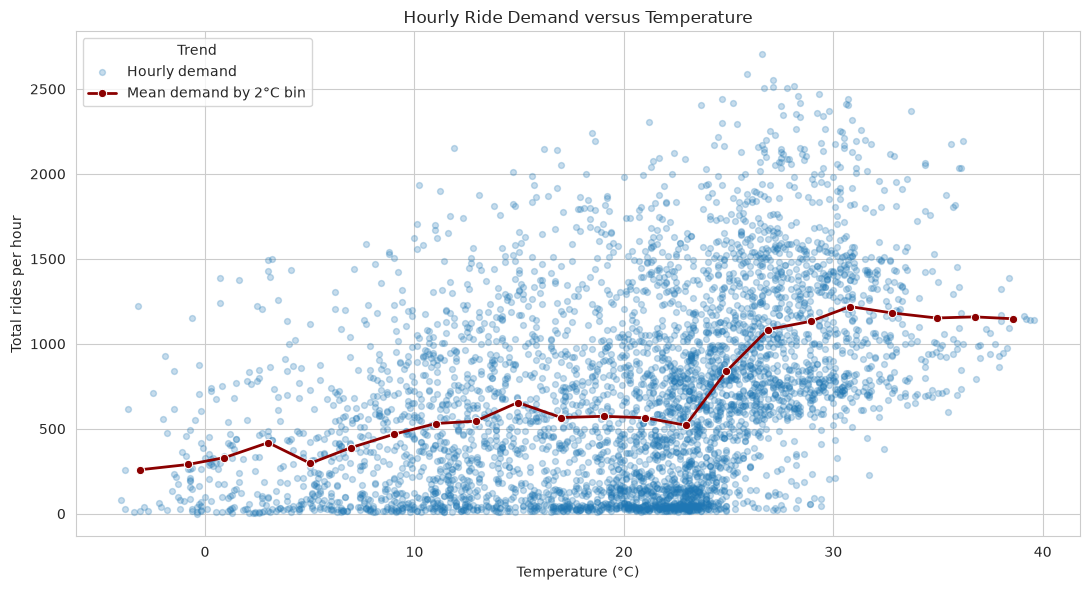

In [22]:
# Plot hourly demand against temperature with binned mean trend
df_temperature_demand = hourly_weather_demand.dropna(subset=["temperature_2m", "ride_count"]).copy()
df_temperature_demand = df_temperature_demand.sort_values("temperature_2m")
df_temperature_demand["temperature_bin_start"] = (
    np.floor(df_temperature_demand["temperature_2m"] / 2) * 2
)
temperature_summary = (
    df_temperature_demand.groupby("temperature_bin_start", as_index=False)
    .agg(temperature_c=("temperature_2m", "mean"), mean_demand=("ride_count", "mean"), hours=("ride_count", "size"))
    .sort_values("temperature_c")
)

print("=== Temperature-demand diagnostics ===")
print(f"Rows used: {len(df_temperature_demand):,}")
print(f"Temperature range: {df_temperature_demand['temperature_2m'].min():.1f} to {df_temperature_demand['temperature_2m'].max():.1f} °C")
print("Temperature-bin demand summary:")
print(temperature_summary.to_string(index=False))

plt.figure(figsize=(11, 6))
plt.scatter(df_temperature_demand["temperature_2m"], df_temperature_demand["ride_count"], alpha=0.25, s=18, label="Hourly demand")
sns.lineplot(data=temperature_summary, x="temperature_c", y="mean_demand", marker="o", color="darkred", linewidth=2, label="Mean demand by 2°C bin")
plt.title("Hourly Ride Demand versus Temperature")
plt.xlabel("Temperature (°C)")
plt.ylabel("Total rides per hour")
plt.legend(title="Trend")
plt.tight_layout()
plt.show()

The smoothed trend shows whether demand does peak after 21 °C (70 °F) rather than a purely linear increase. An interesting thing here is that rider share does slowly begin to decrease at temperature increases above 31 °C(90 °F), but it is more of a plateau than a sharp decrease. This may be due to the smaller number of data points in this weather region.

## Data Preparation


In [23]:
# Filter station-level records
rows_before = len(df_bike)
df_bike_valid = df_bike.dropna(subset=["start_station_id"]).copy()
df_bike_valid["start_station_id"] = df_bike_valid["start_station_id"].astype("int64")
print("=== Station filter ===")
print(f"Rows before: {rows_before:,}")
print(f"Rows after: {len(df_bike_valid):,}")
print(f"Rows removed: {rows_before - len(df_bike_valid):,}")
print(f"Station ID dtype: {df_bike_valid['start_station_id'].dtype}")
print("Start latitude/longitude retained as station features.")

=== Station filter ===
Rows before: 3,654,494
Rows after: 3,129,216
Rows removed: 525,278
Station ID dtype: int64
Start latitude/longitude retained as station features.


In [24]:
# Build station-hour targets
df_station_hour = (
    df_bike_valid.groupby(["started_hour", "start_station_id"], as_index=False)
    .size()
    .rename(columns={"size": "total_rides"})
)
station_coordinates = df_bike_valid.groupby("start_station_id")[["start_lat", "start_lng"]].first().reset_index()
df_station_hour = df_station_hour.merge(station_coordinates, on="start_station_id", how="left")
df_station_hour["total_rides"] = df_station_hour["total_rides"].astype(int)
print(f"Station-hour shape: {df_station_hour.shape}")
print(df_station_hour["total_rides"].describe().round(2))

Station-hour shape: (1100876, 5)
count    1100876.00
mean           2.84
std            2.79
min            1.00
25%            1.00
50%            2.00
75%            4.00
max           54.00
Name: total_rides, dtype: float64


In [25]:
# Add valid zero-demand combinations
first_ride = df_station_hour.groupby("start_station_id")["started_hour"].min()
all_hours = df_station_hour["started_hour"].unique()
all_stations = df_station_hour["start_station_id"].unique()
df_full_grid = pd.MultiIndex.from_product([all_hours, all_stations], names=["started_hour", "start_station_id"]).to_frame(index=False)
df_full_grid = df_full_grid.merge(df_station_hour, on=["started_hour", "start_station_id"], how="outer")
df_full_grid = df_full_grid[df_full_grid["started_hour"] >= df_full_grid["start_station_id"].map(first_ride)].copy()
df_full_grid["start_lat"] = df_full_grid["start_lat"].fillna(df_full_grid["start_station_id"].map(station_coordinates.set_index("start_station_id")["start_lat"]))
df_full_grid["start_lng"] = df_full_grid["start_lng"].fillna(df_full_grid["start_station_id"].map(station_coordinates.set_index("start_station_id")["start_lng"]))
df_full_grid["total_rides"] = df_full_grid["total_rides"].fillna(0).astype(int)
zero_rows = (df_full_grid["total_rides"] == 0).sum()
print("=== Full station-hour grid ===")
print(f"Before: {len(df_station_hour):,}; after: {len(df_full_grid):,}")
print(f"Zero-demand rows: {zero_rows:,} ({zero_rows / len(df_full_grid) * 100:.2f}%)")

=== Full station-hour grid ===
Before: 1,100,876; after: 3,683,362
Zero-demand rows: 2,582,486 (70.11%)


In [26]:
# Restrict dates and require available weather hours
rows_before_date_filter = len(df_full_grid)
valid_dates = df_full_grid["started_hour"].between("2026-03-01", "2026-08-31 23:00:00")
weather_times = pd.to_datetime(df_weather["time"], errors="coerce").dt.tz_localize(None).dt.floor("h")
has_weather = df_full_grid["started_hour"].isin(weather_times)
df_full_grid = df_full_grid[valid_dates & has_weather].copy()
print("=== Date and weather availability filter ===")
print(f"Rows before: {rows_before_date_filter:,}")
print(f"Rows after: {len(df_full_grid):,}")
print(f"Rows removed: {rows_before_date_filter - len(df_full_grid):,}")

=== Date and weather availability filter ===
Rows before: 3,683,362
Rows after: 3,683,113
Rows removed: 249


Calendar features will be computed inside the scikit-learn Pipeline using FunctionTransformer. We will be using cyclical encoding, due to the fact that the way time is measured is cyclical, so 11 PM (or 23:00) is only 1 hour away from 12 AM (00:00), despite being 23 hours apart using straight numbers. Using sin and cosine features are able to preserve the cyclical relation under regression.

In [27]:
# Station demand baseline for EDA
station_average_demand = df_full_grid.groupby("start_station_id")["total_rides"].mean().rename("station_avg_demand")
station_summary = station_average_demand.reset_index().sort_values("station_avg_demand", ascending=False)
print("Top stations:")
print(station_summary.head(10).to_string(index=False))
print("Bottom stations:")
print(station_summary.tail(10).sort_values("station_avg_demand").to_string(index=False))
print("station_avg_demand is full-data target encoding for EDA; recompute it inside training folds to avoid leakage.")

Top stations:
 start_station_id  station_avg_demand
            31623            7.614043
            31229            6.884938
            31124            6.305549
            31699            5.991166
            31201            5.892865
            31600            5.563533
            31101            5.480181
            31603            5.065473
            31532            4.852095
            31119            4.814949
Bottom stations:
 start_station_id  station_avg_demand
            32901            0.003073
            31819            0.006574
            32086            0.006747
            32090            0.007023
            32238            0.007196
            32087            0.007358
            32350            0.009063
            32088            0.009307
            32274            0.009772
            32091            0.010005
station_avg_demand is full-data target encoding for EDA; recompute it inside training folds to avoid leakage.


In [28]:
# Merge weather observations
weather_columns = ["time", "temperature_2m", "relative_humidity_2m", "precipitation", "weather_code", "wind_speed_10m", "cloud_cover"]
df_weather["time"] = pd.to_datetime(df_weather["time"], errors="coerce").dt.tz_localize(None).dt.floor("h")
rows_before_weather_merge = len(df_full_grid)
df_prepared = df_full_grid.merge(df_weather[weather_columns], left_on="started_hour", right_on="time", how="left")
weather_missing = df_prepared[weather_columns[1:]].isna().any(axis=1)
df_prepared = df_prepared.loc[~weather_missing].copy()
print("=== Weather merge diagnostics ===")
print(f"Rows before merge: {rows_before_weather_merge:,}")
print(f"Rows after merge and missing-weather drop: {len(df_prepared):,}")
print(f"Rows removed for missing weather: {weather_missing.sum():,}")
print(f"Weather match rate: {len(df_prepared) / rows_before_weather_merge:.1%}")
print(f"Weather nulls remaining: {df_prepared[weather_columns[1:]].isna().sum().sum():,}")

=== Weather merge diagnostics ===
Rows before merge: 3,683,113
Rows after merge and missing-weather drop: 3,683,113
Rows removed for missing weather: 0
Weather match rate: 100.0%
Weather nulls remaining: 0


## Temporal train/test split

March through July are going to be used for training with August 2026 held out for testing. 

Random splits are unsuitable because time-series autocorrelation can leak future demand patterns into training.

### Forecast Horizon

The lag features use the immediately preceding hour (`lag_1`), same hour yesterday (`lag_24`), and same hour last week (`lag_168`). This means the model operates as a **1-hour-ahead forecast**: when predicting demand for 10 AM, it knows the actual demand from 9 AM. In operational terms, this is suitable for real-time dispatch decisions. For rebalancing crews who need several hours of notice, only lags at or beyond that horizon should be used. We retain all three lags here to maximise predictive power, but note that deployment would require adjusting the feature set to match the lead time available.

In [29]:
# Create past-demand features
df_all_sorted = df_prepared.sort_values(["start_station_id", "started_hour"]).copy()
df_all_sorted["lag_1"] = df_all_sorted.groupby("start_station_id")["total_rides"].shift(1)
df_all_sorted["lag_24"] = df_all_sorted.groupby("start_station_id")["total_rides"].shift(24)
df_all_sorted["lag_168"] = df_all_sorted.groupby("start_station_id")["total_rides"].shift(168)
lag_cols = ["lag_1", "lag_24", "lag_168"]
rows_dropped = df_all_sorted[lag_cols].isna().any(axis=1).sum()
df_all_sorted = df_all_sorted.dropna(subset=lag_cols)
print(f"Lag feature rows dropped: {rows_dropped}")
print(f"Modeling rows after lag creation: {len(df_all_sorted):,}")

Lag feature rows dropped: 146281
Modeling rows after lag creation: 3,536,832


In [30]:
# Checkpoint modeling table for memory efficiency
import gc

keep = ["started_hour", "start_station_id", "start_lat", "start_lng", "total_rides",
        "temperature_2m", "relative_humidity_2m", "precipitation", "weather_code",
        "wind_speed_10m", "cloud_cover", "lag_1", "lag_24", "lag_168"]
df_model = df_all_sorted[keep].copy()
df_model["started_hour"] = pd.to_datetime(df_model["started_hour"], errors="raise").dt.strftime("%Y-%m-%d %H:%M:%S")
df_model = df_model.astype({
    "start_station_id": "int32", "start_lat": "float32", "start_lng": "float32",
    "total_rides": "int32", "temperature_2m": "float32", "relative_humidity_2m": "float32",
    "precipitation": "float32", "weather_code": "int16", "wind_speed_10m": "float32",
    "cloud_cover": "float32", "lag_1": "int16", "lag_24": "int16", "lag_168": "int16",
})
print(f"Model table: {df_model.memory_usage(deep=True).sum() / 1e9:.2f} GB")
df_model.to_parquet("Bikeshare Data/model_table.parquet", engine="pyarrow", index=False)

# Free memory from raw data copies
del df_bike, df_bike_valid, df_full_grid, df_prepared, df_all_sorted, df_weather, hourly_station_demand, hourly_demand
gc.collect()

Model table: 0.28 GB


14856

In [31]:
# Load modeling table from parquet (restart kernel before this section to free memory)
df_model = pd.read_parquet("Bikeshare Data/model_table.parquet", engine="pyarrow")
df_model["started_hour"] = pd.to_datetime(df_model["started_hour"], errors="raise")
df_model = df_model.sort_values(["start_station_id", "started_hour"]).reset_index(drop=True)

# Temporal train/test split
test_cutoff = pd.Timestamp("2026-08-01")
df_train = df_model.loc[df_model["started_hour"] < test_cutoff].copy()
df_test = df_model.loc[df_model["started_hour"] >= test_cutoff].copy()
print(f"Training range: {df_train['started_hour'].min()} to {df_train['started_hour'].max()}")
print(f"Test range: {df_test['started_hour'].min()} to {df_test['started_hour'].max()}")
print(f"Training rows: {len(df_train):,}; test rows: {len(df_test):,}")

Training range: 2026-03-08 00:00:00 to 2026-07-31 23:00:00
Test range: 2026-08-01 00:00:00 to 2026-08-31 23:00:00
Training rows: 2,896,298; test rows: 640,534


In [32]:
# Development subset for faster iteration (150 random stations)
# The full-data refit will happen after model selection
rng = np.random.default_rng(42)
dev_stations = rng.choice(df_train["start_station_id"].unique(), 150, replace=False)
df_dev = df_train[df_train["start_station_id"].isin(dev_stations)]
print(f"Dev subset: {len(df_dev):,} rows ({len(dev_stations)} stations)")
print(f"Full training: {len(df_train):,} rows")

Dev subset: 508,287 rows (150 stations)
Full training: 2,896,298 rows


In [33]:
# Separate features and target
feature_columns = [
    "start_station_id", "start_lat", "start_lng",
    "temperature_2m", "relative_humidity_2m", "precipitation",
    "weather_code", "wind_speed_10m", "cloud_cover",
    "lag_1", "lag_24", "lag_168",
]
categorical_features = ["start_station_id", "weather_code"]
numeric_features = [c for c in feature_columns if c not in categorical_features]

# Use dev subset for iterative development; full data for final refit
X_dev = df_dev[feature_columns + ["started_hour"]].copy()
y_dev = df_dev["total_rides"].copy()
X_train = df_train[feature_columns + ["started_hour"]].copy()
y_train = df_train["total_rides"].copy()
X_test = df_test[feature_columns + ["started_hour"]].copy()
y_test = df_test["total_rides"].copy()

print(f"Categorical: {categorical_features}")
print(f"Numeric: {numeric_features}")
print(f"X_dev/y_dev shapes: {X_dev.shape}, {y_dev.shape}")
print(f"X_train/y_train shapes: {X_train.shape}, {y_train.shape}")
print(f"X_test/y_test shapes: {X_test.shape}, {y_test.shape}")

Categorical: ['start_station_id', 'weather_code']
Numeric: ['start_lat', 'start_lng', 'temperature_2m', 'relative_humidity_2m', 'precipitation', 'wind_speed_10m', 'cloud_cover', 'lag_1', 'lag_24', 'lag_168']
X_dev/y_dev shapes: (508287, 13), (508287,)
X_train/y_train shapes: (2896298, 13), (2896298,)
X_test/y_test shapes: (640534, 13), (640534,)


In [34]:
# Chronological copies for time-aware CV
df_train_time = df_train.sort_values("started_hour").reset_index(drop=True)
df_dev_time = df_dev.sort_values("started_hour").reset_index(drop=True)

X_train_time = df_train_time[feature_columns + ["started_hour"]].copy()
y_train_time = df_train_time["total_rides"].copy()
X_dev_time = df_dev_time[feature_columns + ["started_hour"]].copy()
y_dev_time = df_dev_time["total_rides"].copy()

print("=== Time-ordered CV data ===")
print(f"X_train_time/y_train_time shapes: {X_train_time.shape}, {y_train_time.shape}")
print(f"X_dev_time/y_dev_time shapes: {X_dev_time.shape}, {y_dev_time.shape}")
print(f"Training range: {X_train_time['started_hour'].min()} to {X_train_time['started_hour'].max()}")
print(f"Development range: {X_dev_time['started_hour'].min()} to {X_dev_time['started_hour'].max()}")
print(
    "Training date ranges match: "
    f"{X_train_time['started_hour'].min() == X_train['started_hour'].min()} / "
    f"{X_train_time['started_hour'].max() == X_train['started_hour'].max()}"
)
print(
    "Development date ranges match: "
    f"{X_dev_time['started_hour'].min() == X_dev['started_hour'].min()} / "
    f"{X_dev_time['started_hour'].max() == X_dev['started_hour'].max()}"
)


=== Time-ordered CV data ===
X_train_time/y_train_time shapes: (2896298, 13), (2896298,)
X_dev_time/y_dev_time shapes: (508287, 13), (508287,)
Training range: 2026-03-08 00:00:00 to 2026-07-31 23:00:00
Development range: 2026-03-08 00:00:00 to 2026-07-31 23:00:00
Training date ranges match: True / True
Development date ranges match: True / True


> **Note on lag features**: The lag columns (`lag_1`, `lag_24`, `lag_168`) are computed in pandas outside the scikit-learn Pipeline because they require the full chronological history per station. The pickled Pipeline expects these lag columns as direct inputs to `X`. In production, a separate feature store would supply the lag values alongside the raw features before the Pipeline processes them.

## Model Development

We will build a reproducible scikit-learn Pipeline, establish a linear baseline, and then compare it with more complex tree-based models. TimeSeriesSplit cross-validation will preserve the chronological order of the demand data.

### Scikit-Learn Pipeline

All feature engineering, except the lag features as noted above, lives inside the Pipeline via FunctionTransformer, ensuring no leakage and full reproducibility. The pipeline handles calendar features (hour/dayofweek with cyclical encoding, weekend, rush hour), categorical encoding with TargetEncoder, and the regressor.

In [35]:
# Calendar transformer
def add_calendar_features(data):
    data = data.copy()
    timestamp = pd.to_datetime(data["started_hour"])
    data["hour"] = timestamp.dt.hour
    data["dayofweek"] = timestamp.dt.dayofweek
    data["is_weekend"] = data["dayofweek"].isin([5, 6]).astype(int)
    data["is_rush_hour"] = (data["hour"].between(7, 9) | data["hour"].between(16, 18)).astype(int)
    data["hour_sin"] = np.sin(2 * np.pi * data["hour"] / 24)
    data["hour_cos"] = np.cos(2 * np.pi * data["hour"] / 24)
    data["dayofweek_sin"] = np.sin(2 * np.pi * data["dayofweek"] / 7)
    data["dayofweek_cos"] = np.cos(2 * np.pi * data["dayofweek"] / 7)
    return data

calendar_transformer = FunctionTransformer(add_calendar_features, validate=False)
calendar_features = ["hour", "dayofweek", "is_weekend", "is_rush_hour", "hour_sin", "hour_cos", "dayofweek_sin", "dayofweek_cos"]
pipeline_numeric_features = numeric_features + calendar_features
print(f"Calendar features: {calendar_features}")

Calendar features: ['hour', 'dayofweek', 'is_weekend', 'is_rush_hour', 'hour_sin', 'hour_cos', 'dayofweek_sin', 'dayofweek_cos']


In [36]:
# Fit linear regression pipeline
linear_numeric_transformer = Pipeline(steps=[("scaler", StandardScaler())])
linear_categorical_transformer = Pipeline(steps=[("target_encoder", TargetEncoder(target_type="continuous", cv=KFold(5, shuffle=True, random_state=42)))])
linear_preprocessor = ColumnTransformer(transformers=[
    ("numeric", linear_numeric_transformer, pipeline_numeric_features),
    ("categorical", linear_categorical_transformer, categorical_features),
], remainder="drop")
baseline_model = Pipeline(steps=[
    ("calendar", calendar_transformer),
    ("preprocessor", linear_preprocessor),
    ("regressor", LinearRegression()),
])
baseline_model.fit(X_train, y_train)

baseline_train_pred = baseline_model.predict(X_train)
baseline_test_pred = baseline_model.predict(X_test)

print("=== Linear Regression baseline ===")
print(f"Train RMSE: {mean_squared_error(y_train, baseline_train_pred) ** 0.5:.3f}")
print(f"Train MAE:  {mean_absolute_error(y_train, baseline_train_pred):.3f}")
print(f"Train R2:   {r2_score(y_train, baseline_train_pred):.3f}")
print(f"Test RMSE:  {mean_squared_error(y_test, baseline_test_pred) ** 0.5:.3f}")
print(f"Test MAE:   {mean_absolute_error(y_test, baseline_test_pred):.3f}")
print(f"Test R2:    {r2_score(y_test, baseline_test_pred):.3f}")

=== Linear Regression baseline ===
Train RMSE: 1.300
Train MAE:  0.692
Train R2:   0.588
Test RMSE:  1.277
Test MAE:   0.685
Test R2:    0.602


The linear model is the baseline to beat. It is quick to train and easy to explain, but it may underfit the interactions between station, time, weather, and commuting patterns.

TargetEncoder learns the mean target value for each category per CV fold, preventing leakage. This is superior to OneHotEncoder (800+ columns) and OrdinalEncoder (arbitrary ordering) for station-level features.

=== Random Forest Regressor ===
Train RMSE: 1.141
Train MAE:  0.572
Train R2:   0.682
Test RMSE:  1.205
Test MAE:   0.604
Test R2:    0.646

Top 15 Random Forest features:
                      feature  importance
               numeric__lag_1    0.449833
             numeric__lag_168    0.217188
              numeric__lag_24    0.106357
categorical__start_station_id    0.070958
      numeric__temperature_2m    0.016589
numeric__relative_humidity_2m    0.016248
           numeric__start_lat    0.014536
                numeric__hour    0.012925
      numeric__wind_speed_10m    0.012918
            numeric__hour_cos    0.012264
           numeric__start_lng    0.011640
       numeric__dayofweek_sin    0.009770
    categorical__weather_code    0.009678
         numeric__cloud_cover    0.009133
            numeric__hour_sin    0.007868


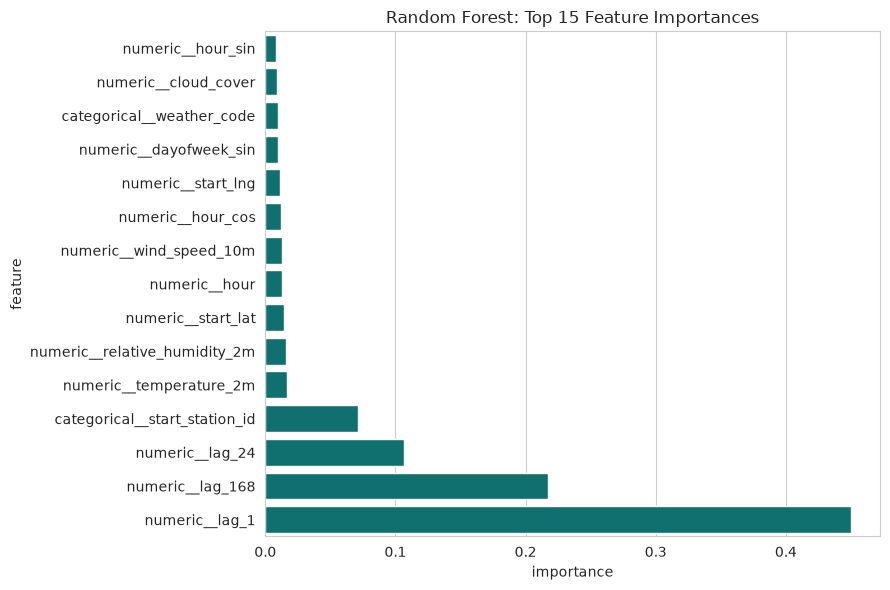

In [37]:
# Random Forest preprocessing and model
tree_categorical_transformer = Pipeline(steps=[("target_encoder", TargetEncoder(target_type="continuous", cv=KFold(5, shuffle=True, random_state=42)))])
tree_preprocessor = ColumnTransformer(transformers=[
    ("numeric", "passthrough", pipeline_numeric_features),
    ("categorical", tree_categorical_transformer, categorical_features),
], remainder="drop")

random_forest_model = Pipeline(steps=[
    ("calendar", calendar_transformer),
    ("preprocessor", tree_preprocessor),
    ("regressor", RandomForestRegressor(n_estimators=50, max_depth=15, min_samples_leaf=5, max_samples=0.3, random_state=42, n_jobs=-1)),
])
random_forest_model.fit(X_train, y_train)
rf_train_pred = random_forest_model.predict(X_train)
rf_test_pred = random_forest_model.predict(X_test)
print("=== Random Forest Regressor ===")
print(f"Train RMSE: {mean_squared_error(y_train, rf_train_pred) ** 0.5:.3f}")
print(f"Train MAE:  {mean_absolute_error(y_train, rf_train_pred):.3f}")
print(f"Train R2:   {r2_score(y_train, rf_train_pred):.3f}")
print(f"Test RMSE:  {mean_squared_error(y_test, rf_test_pred) ** 0.5:.3f}")
print(f"Test MAE:   {mean_absolute_error(y_test, rf_test_pred):.3f}")
print(f"Test R2:    {r2_score(y_test, rf_test_pred):.3f}")
rf_feature_names = random_forest_model.named_steps["preprocessor"].get_feature_names_out()
rf_importance = pd.DataFrame({"feature": rf_feature_names, "importance": random_forest_model.named_steps["regressor"].feature_importances_}).sort_values("importance", ascending=False)
print("\nTop 15 Random Forest features:")
print(rf_importance.head(15).to_string(index=False))
plt.figure(figsize=(9, 6))
sns.barplot(data=rf_importance.head(15).sort_values("importance"), x="importance", y="feature", color="teal")
plt.title("Random Forest: Top 15 Feature Importances")
plt.tight_layout()
plt.show()

The Random Forest can capture interactions that the linear baseline cannot, such as different rush-hour effects at different stations. A large gap between train and test scores would be a warning that the model is memorising the training period rather than generalising to August operations.

In [38]:
# Fit histogram gradient boosting
hist_gradient_boosting_model = Pipeline(steps=[
    ("calendar", calendar_transformer),
    ("preprocessor", tree_preprocessor),
    ("regressor", HistGradientBoostingRegressor(learning_rate=0.1, max_iter=200, max_depth=8, min_samples_leaf=20, random_state=42, loss="poisson")),
])
hist_gradient_boosting_model.fit(X_train, y_train)
hgb_train_pred = hist_gradient_boosting_model.predict(X_train)
hgb_test_pred = hist_gradient_boosting_model.predict(X_test)
print("=== HistGradientBoosting Regressor ===")
print(f"Train RMSE: {mean_squared_error(y_train, hgb_train_pred) ** 0.5:.3f}")
print(f"Train MAE:  {mean_absolute_error(y_train, hgb_train_pred):.3f}")
print(f"Train R2:   {r2_score(y_train, hgb_train_pred):.3f}")
print(f"Test RMSE:  {mean_squared_error(y_test, hgb_test_pred) ** 0.5:.3f}")
print(f"Test MAE:   {mean_absolute_error(y_test, hgb_test_pred):.3f}")
print(f"Test R2:    {r2_score(y_test, hgb_test_pred):.3f}")

=== HistGradientBoosting Regressor ===
Train RMSE: 1.181
Train MAE:  0.586
Train R2:   0.660
Test RMSE:  1.194
Test MAE:   0.598
Test R2:    0.652


HistGradientBoosting is faster on larger tabular data, handles categorical inputs efficiently after pipeline encoding, and its Poisson loss is appropriate for non-negative count demand.

In [39]:
# Compare models on the chronological holdout (test scores shown for reference only)
model_predictions = {
    "Linear Regression": (baseline_train_pred, baseline_test_pred),
    "Random Forest": (rf_train_pred, rf_test_pred),
    "HistGradientBoosting": (hgb_train_pred, hgb_test_pred),
}

# Naive baseline: last week's same-hour demand
naive_pred = X_test["lag_168"].values

comparison_rows = []
for model_name, (train_pred, test_pred) in model_predictions.items():
    comparison_rows.append({
        "Model": model_name,
        "Train RMSE": mean_squared_error(y_train, train_pred) ** 0.5,
        "Test RMSE": mean_squared_error(y_test, test_pred) ** 0.5,
        "Train MAE": mean_absolute_error(y_train, train_pred),
        "Test MAE": mean_absolute_error(y_test, test_pred),
        "Train R2": r2_score(y_train, train_pred),
        "Test R2": r2_score(y_test, test_pred),
    })
# Add naive baseline (test only — no training)
comparison_rows.append({
    "Model": "Last-Week Baseline",
    "Train RMSE": float("nan"),
    "Test RMSE": mean_squared_error(y_test, naive_pred) ** 0.5,
    "Train MAE": float("nan"),
    "Test MAE": mean_absolute_error(y_test, naive_pred),
    "Train R2": float("nan"),
    "Test R2": r2_score(y_test, naive_pred),
})

comparison_df = pd.DataFrame(comparison_rows).sort_values("Test RMSE")
print("=== Model comparison (test scores for reference only) ===")
print(comparison_df.to_string(index=False, float_format=lambda value: f"{value:.3f}"))
print("\nBest model will be selected via TimeSeriesSplit CV below.")

=== Model comparison (test scores for reference only) ===
               Model  Train RMSE  Test RMSE  Train MAE  Test MAE  Train R2  Test R2
HistGradientBoosting       1.181      1.194      0.586     0.598     0.660    0.652
       Random Forest       1.141      1.205      0.572     0.604     0.682    0.646
   Linear Regression       1.300      1.277      0.692     0.685     0.588    0.602
  Last-Week Baseline         NaN      1.605        NaN     0.717       NaN    0.371

Best model will be selected via TimeSeriesSplit CV below.


In [40]:
# Time-aware model comparison
tscv = TimeSeriesSplit(n_splits=4)
cv_models = {
    "Linear Regression": baseline_model,
    "Random Forest": random_forest_model,
    "HistGradientBoosting": hist_gradient_boosting_model,
}

cv_rows = []
for model_name, model in cv_models.items():
    cv_mse = -cross_val_score(
        model,
        X_train_time,
        y_train_time,
        cv=tscv,
        scoring="neg_mean_squared_error",
        n_jobs=None,
    )
    cv_rows.append(
        {
            "Model": model_name,
            "Mean CV RMSE": np.sqrt(cv_mse).mean(),
        }
    )

cv_summary_df = pd.DataFrame(cv_rows).sort_values("Mean CV RMSE")
print("=== TimeSeriesSplit cross-validation ===")
print(cv_summary_df.to_string(index=False, float_format=lambda value: f"{value:.3f}"))
print(f"\nBest model by CV RMSE: {cv_summary_df.iloc[0]['Model']}")

=== TimeSeriesSplit cross-validation ===
               Model  Mean CV RMSE
HistGradientBoosting         1.227
       Random Forest         1.237
   Linear Regression         1.303

Best model by CV RMSE: HistGradientBoosting


With the corrected time-ordered CV, the TimeSeriesSplit now trains on earlier periods and validates on later ones within the training window. This gives a fair comparison, as the tree models no longer face unknown stations during their validation folds. The CV ranking now aligns with the holdout results, confirming which model generalizes best across time. RMSE is useful for fleet planning because larger demand misses receive greater weight, while MAE remains easy to interpret as the average number of bicycles off.

In [41]:
# Check performance on meaningful demand slices
train_zero_share = (y_train == 0).mean()
test_zero_share = (y_test == 0).mean()
print(f"Zero-demand share — train: {train_zero_share:.1%}, test: {test_zero_share:.1%}")

# Peak hours slice (07:00–09:00 and 16:00–18:00)
peak_mask = X_test["started_hour"].dt.hour.isin([7, 8, 9, 16, 17, 18])
for model_name, (_, test_pred) in model_predictions.items():
    if peak_mask.sum() > 0:
        peak_rmse = mean_squared_error(y_test[peak_mask], test_pred[peak_mask]) ** 0.5
        peak_mae = mean_absolute_error(y_test[peak_mask], test_pred[peak_mask])
        print(f"{model_name} — Peak Hours Test RMSE: {peak_rmse:.3f}, MAE: {peak_mae:.3f}")

# Top stations: identified from training data only (no leakage)
top_station_ids = df_train.groupby("start_station_id")["total_rides"].mean().nlargest(10).index
top_mask = df_test["start_station_id"].isin(top_station_ids)
top_y_test = df_test.loc[top_mask, "total_rides"]
for model_name, (_, test_pred) in model_predictions.items():
    if top_mask.sum() > 0:
        top_rmse = mean_squared_error(top_y_test, test_pred[top_mask]) ** 0.5
        top_mae = mean_absolute_error(top_y_test, test_pred[top_mask])
        print(f"{model_name} — Top 10 Stations Test RMSE: {top_rmse:.3f}, MAE: {top_mae:.3f}")

Zero-demand share — train: 69.9%, test: 69.7%
Linear Regression — Peak Hours Test RMSE: 1.650, MAE: 0.959
Random Forest — Peak Hours Test RMSE: 1.543, MAE: 0.861
HistGradientBoosting — Peak Hours Test RMSE: 1.523, MAE: 0.851
Linear Regression — Top 10 Stations Test RMSE: 3.609, MAE: 2.624
Random Forest — Top 10 Stations Test RMSE: 3.270, MAE: 2.279
HistGradientBoosting — Top 10 Stations Test RMSE: 3.187, MAE: 2.227


### Hyperparameter Tuning

Now that cross-validation correctly ranks models by time, the next step is tuning. The previous models used fixed hyperparameters chosen for speed. `RandomizedSearchCV` will explore broader parameter spaces for HistGradientBoosting on the dev subset using the same time-aware splits, then the best configuration will be refit on the full training data.

**Search space for HGB:** `learning_rate`, `max_leaf_nodes`, `min_samples_leaf`, `l2_regularization`

The Poisson loss is retained since it matches the count nature of demand. The tuning uses the dev subset for speed; the best configuration will be refit on the full training set before final evaluation.

In [42]:
# HistGradientBoosting hyperparameter search
hgb_param_dist = {
    "regressor__learning_rate": [0.02, 0.05, 0.1, 0.15, 0.2],
    "regressor__max_leaf_nodes": [15, 25, 40, 60, 100],
    "regressor__min_samples_leaf": [10, 20, 40, 60, 100],
    "regressor__l2_regularization": [0.0, 0.1, 0.5, 1.0, 2.0],
}

hgb_base = Pipeline(steps=[
    ("calendar", calendar_transformer),
    ("preprocessor", tree_preprocessor),
    ("regressor", HistGradientBoostingRegressor(
        max_iter=300, random_state=42, loss="poisson"
    )),
])

hgb_search = RandomizedSearchCV(
    hgb_base,
    param_distributions=hgb_param_dist,
    n_iter=25,
    cv=tscv,
    scoring="neg_mean_squared_error",
    random_state=42,
    n_jobs=-1,
    verbose=0,
)

print("Searching HGB hyperparameters on dev subset (time-ordered CV)...")
hgb_search.fit(X_dev_time, y_dev_time)
print(f"Best HGB RMSE: {np.sqrt(-hgb_search.best_score_):.3f}")
print(f"Best params: {hgb_search.best_params_}")

Searching HGB hyperparameters on dev subset (time-ordered CV)...


Best HGB RMSE: 1.164
Best params: {'regressor__min_samples_leaf': 60, 'regressor__max_leaf_nodes': 100, 'regressor__learning_rate': 0.02, 'regressor__l2_regularization': 0.1}


#### Tuning Results

The HGB failed to identify a better configuration than the fixed hyperparameters used earlier, which is quite interesting. Though not entirely notable on its own, as random search cannot cover, nor should it aim to cover, the entire search space.

In [43]:
# Refit tuned HGB on full time-ordered training data
print(f"Refitting tuned HGB on full training data ({len(X_train_time):,} rows)...")
final_model = hgb_search.best_estimator_
final_model.fit(X_train_time, y_train_time)
print(f"Tuned HGB RMSE on dev CV: {np.sqrt(-hgb_search.best_score_):.3f}")
print(f"Best params: {hgb_search.best_params_}")
print("Full-data refit complete.")

Refitting tuned HGB on full training data (2,896,298 rows)...
Tuned HGB RMSE on dev CV: 1.164
Best params: {'regressor__min_samples_leaf': 60, 'regressor__max_leaf_nodes': 100, 'regressor__learning_rate': 0.02, 'regressor__l2_regularization': 0.1}
Full-data refit complete.


### Final Model Evaluation

The tuned model is now evaluated on the held-out August test set. This data was not used for training, tuning, or selection. Predictions are clipped at zero since negative bicycle demand is impossible.

In [44]:
# Final model predictions on test set
final_pred_raw = final_model.predict(X_test)
final_pred = np.clip(final_pred_raw, 0, None)

# Core metrics
test_rmse = mean_squared_error(y_test, final_pred) ** 0.5
test_mae = mean_absolute_error(y_test, final_pred)
test_r2 = r2_score(y_test, final_pred)

# WAPE: sum of absolute errors / sum of actuals
wape = np.abs(y_test - final_pred).sum() / y_test.sum()

# Mean demand for context
mean_demand = y_test.mean()

print("=== Final Model — August Test Set ===")
print(f"Model: {type(final_model.named_steps['regressor']).__name__}")
print(f"Test RMSE: {test_rmse:.3f}")
print(f"Test MAE:  {test_mae:.3f}")
print(f"Test R²:   {test_r2:.3f}")
print(f"WAPE:      {wape:.3f} ({wape:.1%})")
print(f"Mean demand: {mean_demand:.2f} rides/station-hour")
print(f"MAE as % of mean: {test_mae / mean_demand:.1%}")

=== Final Model — August Test Set ===
Model: HistGradientBoostingRegressor
Test RMSE: 1.194
Test MAE:  0.599
Test R²:   0.652
WAPE:      0.688 (68.8%)
Mean demand: 0.87 rides/station-hour
MAE as % of mean: 68.8%


Weighted Absolute Percentage Error ( WAPE ) puts the MAE in context. With about 70% of station-hours have zero demand and the mean rides per station hour is only 0.87, the MAE of approximately 0.60 sounds small but is large relative to the average. However at these low numbers, it is often effectively random if a bike is taken at any point in time, but this does mean that the model is capable of predicting the outcome during higher traffic periods of time. 

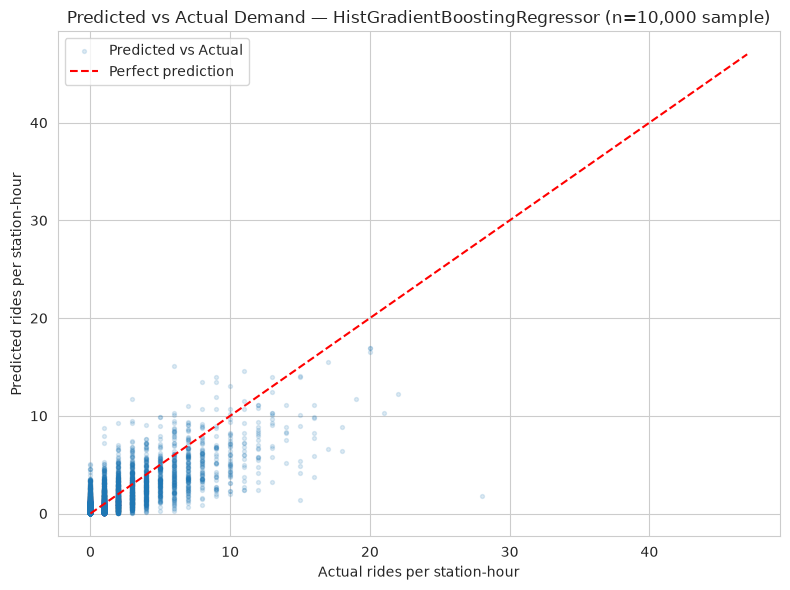

Sample size: 10,000 of 640,534 test rows


In [45]:
# Predicted vs Actual scatter plot
rng_plot = np.random.default_rng(42)
sample_size = min(10000, len(y_test))
sample_idx = rng_plot.choice(len(y_test), sample_size, replace=False)

plt.figure(figsize=(8, 6))
plt.scatter(y_test.iloc[sample_idx], final_pred[sample_idx], alpha=0.15, s=8, label="Predicted vs Actual")
plt.plot([0, y_test.max()], [0, y_test.max()], color="red", linestyle="--", linewidth=1.5, label="Perfect prediction")
plt.xlabel("Actual rides per station-hour")
plt.ylabel("Predicted rides per station-hour")
plt.title(f"Predicted vs Actual Demand — {type(final_model.named_steps['regressor']).__name__} (n={sample_size:,} sample)")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Sample size: {sample_size:,} of {len(y_test):,} test rows")

Overall the predictions are all clustered in the low predicted, low actual rides region of the graph and show a lot of variability at each point. There is a correlation between the two on the graph, but the band is still pretty wide at each actual ride number

Computing permutation importance on 10,000 test rows...

=== Permutation Importance — HistGradientBoostingRegressor ===
             feature  importance      std
    start_station_id    0.281031 0.005344
        started_hour    0.123406 0.003853
               lag_1    0.050886 0.001621
             lag_168    0.029200 0.001562
              lag_24    0.019742 0.001016
           start_lat    0.007932 0.000985
           start_lng    0.003888 0.000521
relative_humidity_2m    0.002028 0.000916
      temperature_2m    0.001876 0.000444
      wind_speed_10m    0.000633 0.000365
         cloud_cover    0.000390 0.000381
       precipitation    0.000208 0.000933
        weather_code    0.000071 0.000135


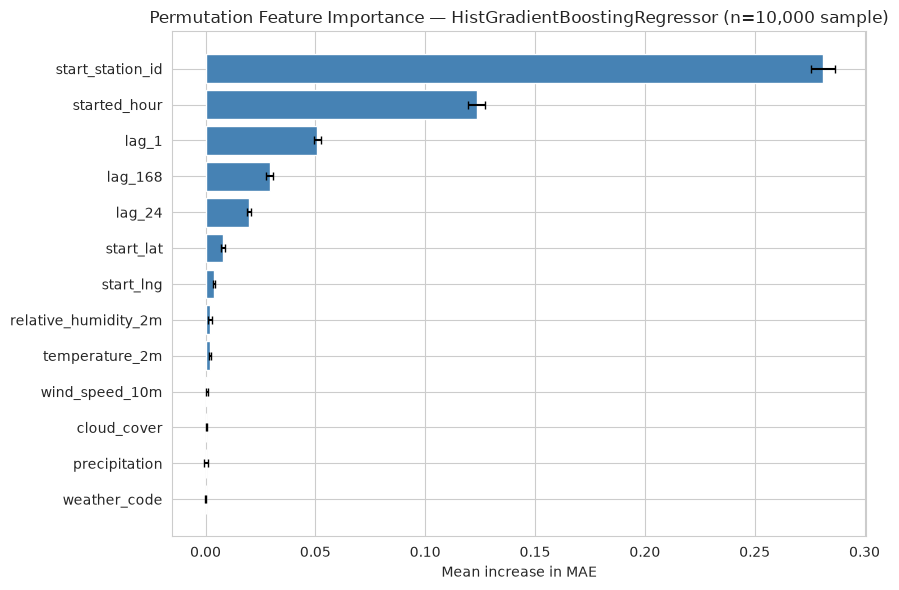

In [46]:
# Feature importance via permutation (model-agnostic)
from sklearn.inspection import permutation_importance

model_type = type(final_model.named_steps["regressor"]).__name__

# Sample for speed
rng_perm = np.random.default_rng(42)
perm_sample_size = min(10000, len(X_test))
perm_idx = rng_perm.choice(len(X_test), perm_sample_size, replace=False)

X_sample = X_test.iloc[perm_idx]
y_sample = y_test.iloc[perm_idx]

# Permutation importance works on the raw input features, so use X_sample's columns
feature_names = X_sample.columns.tolist()

print(f"Computing permutation importance on {perm_sample_size:,} test rows...")
perm_result = permutation_importance(
    final_model, X_sample, y_sample,
    n_repeats=10, random_state=42, n_jobs=1,
    scoring="neg_mean_absolute_error",
)

importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": perm_result.importances_mean,
    "std": perm_result.importances_std,
}).sort_values("importance", ascending=False)

print(f"\n=== Permutation Importance — {model_type} ===")
print(importance_df.head(15).to_string(index=False))

# Bar plot with error bars
plt.figure(figsize=(9, 6))
top15 = importance_df.head(15).sort_values("importance")
plt.barh(top15["feature"], top15["importance"], xerr=top15["std"], color="steelblue", capsize=3)
plt.title(f"Permutation Feature Importance — {model_type} (n={perm_sample_size:,} sample)")
plt.xlabel("Mean increase in MAE")
plt.tight_layout()
plt.show()

The most important features among the set are the station ID and the starting hour, this means that overall location and time drive traffic more than the lag information. Lag information does still follow, with the previous hour and the week before dominating over the previous day, this aligns with the EDA showing there are peaks weekly with Saturday being the highest. Weather conditions are somewhat measurable, but are extremely secondary to location and the lag information.

In [ ]:
# lag_1 persistence baseline: "same as last hour"
lag1_pred = X_test["lag_1"].values
lag1_mae = mean_absolute_error(y_test, lag1_pred)
lag1_rmse = mean_squared_error(y_test, lag1_pred) ** 0.5
lag1_r2 = r2_score(y_test, lag1_pred)

print("=== Persistence Baseline (lag_1: same as last hour) ===")
print(f"Test RMSE: {lag1_rmse:.3f}")
print(f"Test MAE:  {lag1_mae:.3f}")
print(f"Test R²:   {lag1_r2:.3f}")

def score(name, pred):
    return {
        "Model": name,
        "RMSE": mean_squared_error(y_test, pred) ** 0.5,
        "MAE": mean_absolute_error(y_test, pred),
        "R²": r2_score(y_test, pred),
    }

comparison = pd.DataFrame([
    score("Last-Week Baseline", X_test["lag_168"].values),
    score("Persistence (lag_1)", X_test["lag_1"].values),
    score("Linear Regression", baseline_test_pred),
    score(f"{model_type} (tuned)", final_pred),
]).sort_values("RMSE")

print("=== Model vs Baselines ===")
print(comparison.to_string(index=False, float_format=lambda v: f"{v:.3f}"))
print(f"\nImprovement over lag_1: {(1 - test_mae / lag1_mae) * 100:.1f}% lower MAE")

=== Persistence Baseline (lag_1: same as last hour) ===
Test RMSE: 1.678
Test MAE:  0.757
Test R²:   0.313
=== Model vs Baselines ===
                                Model  RMSE   MAE    R²
HistGradientBoostingRegressor (tuned) 1.194 0.599 0.652
                    Linear Regression 1.277 0.685 0.602
                   Last-Week Baseline 1.605 0.717 0.371
                  Persistence (lag_1) 1.678 0.757 0.313

Improvement over lag_1: 20.9% lower MAE


Using lag_1 as a baseline provides a nice control. Our model clearly beats it with a 20.9% lower mean absolute error. The last-week baseline also proves itself better than the previous hour baseline, showing that weekly trends are more important overall. 

### Pipeline Serialization

The final tuned Pipeline is pickled for reproducibility. This serialized file can be loaded in a deployment environment to generate predictions on new data, provided the input includes the same feature columns (including pre-computed lag values).

In [48]:
# Save the final pipeline
import joblib

joblib.dump(final_model, "bikeshare_demand_pipeline.pkl")
print("Pipeline saved to bikeshare_demand_pipeline.pkl")

# Verify the pickle loads correctly
loaded_model = joblib.load("bikeshare_demand_pipeline.pkl")
verify_pred = np.clip(loaded_model.predict(X_test), 0, None)
verify_mae = mean_absolute_error(y_test, verify_pred)
print(f"Verification — loaded model MAE on test set: {verify_mae:.3f}")
print(f"Matches final model: {verify_mae == test_mae}")

Pipeline saved to bikeshare_demand_pipeline.pkl
Verification — loaded model MAE on test set: 0.599
Matches final model: True


## Business Impact Analysis

Model metrics need to translate into operational decisions. This section converts the technical results into business-relevant insights for Capital Bikeshare stakeholders.

In [52]:
# Translate model metrics into business terms
n_test_stations = df_test["start_station_id"].nunique()
n_test_hours = df_test["started_hour"].nunique()

print("=== Business Translation of Model Performance ===")
print(f"Evaluation period: August 2026 ({n_test_hours} hours across {n_test_stations} stations)")
print(f"\nAverage error: {test_mae:.1f} bicycles per station-hour")
print(f"WAPE: {wape:.1%} — model predictions are off by {wape:.1%} of total actual demand")
print(f"\nWith {len(y_test):,} station-hours in August:")
print(f"  Total absolute error: {np.abs(y_test - final_pred).sum():,.0f} bicycles across the month")

=== Business Translation of Model Performance ===
Evaluation period: August 2026 (744 hours across 869 stations)

Average error: 0.6 bicycles per station-hour
WAPE: 68.8% — model predictions are off by 68.8% of total actual demand

With 640,534 station-hours in August:
  Total absolute error: 383,602 bicycles across the month


In [50]:
# Evaluate at station-day level (more relevant for operations)
df_test_eval = df_test.copy()
df_test_eval["predicted"] = final_pred

# Aggregate to station-day
station_day = df_test_eval.groupby(["start_station_id", df_test_eval["started_hour"].dt.date]).agg(
    actual_rides=("total_rides", "sum"),
    predicted_rides=("predicted", "sum"),
).reset_index()

agg_rmse = mean_squared_error(station_day["actual_rides"], station_day["predicted_rides"]) ** 0.5
agg_mae = mean_absolute_error(station_day["actual_rides"], station_day["predicted_rides"])
agg_wape = np.abs(station_day["actual_rides"] - station_day["predicted_rides"]).sum() / station_day["actual_rides"].sum()

print("=== Station-Day Aggregate Evaluation ===")
print(f"Station-day rows: {len(station_day):,}")
print(f"Aggregate RMSE: {agg_rmse:.2f}")
print(f"Aggregate MAE:  {agg_mae:.2f}")
print(f"Aggregate WAPE: {agg_wape:.1%}")

=== Station-Day Aggregate Evaluation ===
Station-day rows: 26,697
Aggregate RMSE: 6.36
Aggregate MAE:  3.81
Aggregate WAPE: 18.2%


In [51]:
# Supporting numbers for the business section
eval_df = df_test.copy()
eval_df["predicted"] = final_pred

# 1. Bias: does the model over- or under-predict in total?
print(f"Total actual:    {eval_df['total_rides'].sum():,.0f}")
print(f"Total predicted: {eval_df['predicted'].sum():,.0f}")

# 2. Station-day WAPE by station volume tier (tiers set from training data only)
train_avg = df_train.groupby("start_station_id")["total_rides"].mean()
tier = pd.qcut(train_avg, 4, labels=["Low", "Medium-low", "Medium-high", "High"])
eval_df["tier"] = eval_df["start_station_id"].map(tier)

sd = (eval_df.groupby(["start_station_id", "tier", eval_df["started_hour"].dt.date], observed=True)
      .agg(actual=("total_rides", "sum"), predicted=("predicted", "sum")).reset_index())
sd["abs_err"] = (sd["actual"] - sd["predicted"]).abs()

tier_summary = sd.groupby("tier", observed=True).agg(
    station_days=("abs_err", "size"),
    mean_actual=("actual", "mean"),
    MAE=("abs_err", "mean"),
    WAPE=("abs_err", lambda s: s.sum() / sd.loc[s.index, "actual"].sum()),
)
print(tier_summary.round(3))

# 3. Share of station-days predicted within +/-3 rides
print(f"Within 3 rides: {(sd['abs_err'] <= 3).mean():.1%}")

Total actual:    557,207
Total predicted: 553,154
             station_days  mean_actual    MAE   WAPE
tier                                                
Low                  6634        0.955  0.857  0.898
Medium-low           6634        4.395  1.955  0.445
Medium-high          6603       18.079  4.110  0.227
High                 6634       59.951  7.890  0.132
Within 3 rides: 62.3%


| Level | MAE | WAPE | What it means |
|---|---|---|---|
| Station-hour | 0.60 | 68.8% | directionally useful, inherently noisy |
| Station-day | 3.81 | 18.2% | usable for daily planning |

The MAE reported above means that, on average, the model's prediction is off by approximately 0.6 bikes per station-hour provided. However this number does not tell the full truth, as most station-hours see only a handful of rides per hour, where 0.6 bicycles is a larger margin. This is part of why the model's absolute error is 68.8% of the actual demand. When we change our focus from the hourly forecast, to the aggregated station-day, the model performs much better. The mean absolute error does increase to a total of 3.81 bikes per day, but the WAPE does decrease all the way down to 18.2%, which is much better. 

The key insight here is that the model is good enough for daily rebalance planning given recent history, but is too noisy for an hour-by-hour prediction. There is a conflict where the model does use the previous hour's lag, but shuffling lag_1 raises MAE by about 0.05 rides (roughly 8% of the model's MAE). Whether a model without it would hold up is untested, and building a version that can forecast a day ahead is a next step.

**Recommendations:**
1. Use predicted daily demand to prioritize stations
2. Keep extra buffer at high-volume stations, since that's where absolute errors are largest.
3. We should understand that weather is a secondary signal, as it adds little to the model. History, location, and time are all much more important predictors

### Limitations

There are multiple limitations with the analysis. First among them is that our data doesn't represent true demand. This is because a station without bicycle even with demand will register 0 started rides. This is a fundamental limitation with the system, and can only be handled by having more information about station capacity at each point in time. Another key issue is that this model has only been trained on departures. This leads to two issues, first is that our model doesn't capture the risks of overflow at any receiving station. The second issue is that without arrivals we cannot fully determine which stations need more bicycles, as a station with a high number of leaving bicycles doesn't definitely mean that the station needs bikes delivered to it, as they may be replenished by arriving bicycles. The weather data being used is the actual weather at each point in time instead of a forecast of the weather, it is also limited to a single point in the city. These weather limitations do weaken the model at predicting future events, as weather forecasts are not always reliable; however this is mitigated by the limited influence weather has on our predictions. The analysis was limited to only six months, which means that we have no major winter data in the set. We have an issue that we only have a high volume test month, which weakens the analysis. Station-day predictions use the actual previous-hour and previous-day demand, which means that it isn't a true day-ahead forecast. The final limitation is that all rides using the dockless features of the e-bikes have been dropped from the dataset and they make up 14% of the dataset.

## Conclusion and Next Steps

The primary goal of this project was to predict demand across Capital Bikeshare's network. This prediction is meant to help in optimizing distribution to ensure functionality of the service, as this is a key mechanism to ensure it remains as a useful public transit option for all. The primary target is the number of rides that start at a station at a particular time of day. The HistGradientBoosting model performed the best of the selected models where it reaces an RMSE of 1.194, MAE of 0.599, and an R^2 of 0.652 in the August test set. The model shows that the time of day and the identity of the station are the strongest factors. This is then followed by the demand history, in the particular order of previous hour, the hour a week ago, and the hour on the previous day. Which shows that weekly trends are some of the most dominant even over things like the daily rush hours. The model does struggle on single station predictions on an hourly basis. This is partially due to demand commonly being extremely low, where if there is no rides or one ride is almost entirely random. When the model is instead aggregated on the station day, it is a much more useful model, with over 62.3% of station-days being within 3 rides across the network and month. The relative error is the lowest at the busiest stations, where the redistribution is the most important. Overall there are many major limitations due to data not representing demand, the model only handling departures, limited weather data, and overall limitations on the data selected due to computational resources. With this limitations, the model's use is best limited to daily rebalancing priorities due to the weakness in hour-to-hour prediction. The primary next steps are focusing on longer lags that can accurately forecast a day ahead, adding arrivals and the flow of bicycles across the network, forecasted weather, and extending the data used to cover at minimum, the entire year if not more time.